<a href="https://colab.research.google.com/github/dsb4k8/Machine-Learning/blob/main/Diego_Brown_Stat_Learning_Lab_Subset_Selection_(Resampling)_%26_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Section 1-Cross-Validation and Bootstrap :

# Subset Selection - Cross Validation and the Bootstrap
_Cross-validation and the bootstrap are two of the most powerful resampling techniques used to assess a model's performance and quantify the uncertainty of its estimates without requiring a completely new dataset._


In [45]:
##Grabbing the ISLR library: https://cran.r-project.org/web/packages/ISLR2/index.html
install.packages("ISLR")
install.packages("boot")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



##Validation set approach
Validation sets can be used to estimate test error rated resulting from fitting various linear models (lm) on - in this case - automotive data


For random sampling, RNG is required - but RNG alone introduces problems for reproducability.

For this reason, we first set a fixed `seed value` such that your machine produces the same random values as mine.



### TASK 1)  Change the value of the seed for (Validation Set Approach) part 1 to the last 4 numbers of your student ID .

Report the test rates for a Poly fit quadratic and cubic using the seed. -- IMPORTANT: your assignment will only be graded if you use the last 4 numbers of your student ID as the seed.  

In [46]:
library(ISLR)
library(glue)
set.seed(7829)

##Splitting the data into different Test / Training Ratios
The `sample()` method is used for splitting the data into 2 subsets.
- First,
generating a dataset of numbers from [1 - 392],
- then,
taking 192 if them at random and assigning them to the variable train.
This variable stores our training set

_for docs, run `?sample` in a separate cell._

In [47]:
train.50 <-sample(392, 196)

For the sake of comparison, lets test a few other splits:
we already have a 50/50 training. lets also do:

- 60%, 70%, and 80%

test percentage splits

In [48]:
392 * 0.5
392 * 0.6
392 * .7
392 * .8

[1] 196

[1] 235.2

[1] 274.4

[1] 313.6

####Splitting the data + Quality of Life Update

Since we are working with 4 configuations, lets make a function which wraps the core logic - allowing us just to pass the appropiate parameters


### TASK 2) Change the ratio of train/test to a new percentage. (original was 50/50)

- Select 3 new ratios and compute and report the test performance for each using the best performing of the two Poly fit values from task 1. Keep your student ID as the seed.

In [49]:
validation.split <- function(total_pop, trainPercentage) {
  #Resetting the seed for each split to ensure we are comparing apples to apples
  #otherwise the seed with drift with each sample call (within validation.split)
  set.seed(7829)
  return (sample(total_pop, total_pop*trainPercentage))
}
train.60 <- validation.split(392, 0.60) # 235
train.70 <- validation.split(392, 0.70) # 274
train.80 <- validation.split(392, 0.80) # 313

##Running Linear Regression on the training sets
We now have 4 lists of 4 sample sizes:


`train.60` for example contains a list of 235 randomly sampled numbers taken from the original set  (1 - 392).

We use this list of random integers as indicies against the cohort of 392.

Then we fit the data using linear regression - comparing mpg against horsepower using the subset of data we sampled.

In [50]:
lm.fit50 <- lm(mpg ~ horsepower, data = Auto, subset = train.50)
lm.fit50
lm.fit60 <- lm(mpg ~ horsepower, data = Auto, subset = train.60)
lm.fit70 <- lm(mpg ~ horsepower, data = Auto, subset = train.70)
lm.fit80 <- lm(mpg ~ horsepower, data = Auto, subset = train.80)


Call:
lm(formula = mpg ~ horsepower, data = Auto, subset = train.50)

Coefficients:
(Intercept)   horsepower  
    39.6088      -0.1548  


In [51]:
attach(Auto)

The following object is masked from package:ggplot2:

    mpg




###Calculating Mean Squared Error - MSE
`predict()` estimates the response for all observations

`mean()` will calculate the MSE for all 196 observations in the validation set.

`-train`: is the syntax to use when we only want to select observations which are NOT in the training set

Below, im simply calculating MSE using the y (actual mpg), and y-hat (predicted) across each or our seeded random samples

In [52]:
m1 <- mean((mpg - predict(lm.fit50, Auto))[-train.50]^2)
glue("MSE with sample val size 196: {m1}")

m2 <- mean((mpg - predict(lm.fit60, Auto))[-train.60]^2)
glue("MSE with sample size 235: {m2}")

m3 <- mean((mpg - predict(lm.fit70, Auto))[-train.70]^2)
glue("MSE with sample size 274: {m3}")

m4 <- mean((mpg - predict(lm.fit80, Auto))[-train.80]^2)
glue("MSE with sample size 313: {m4}")



MSE with sample val size 196: 24.2771653209809

MSE with sample size 235: 22.9379588335834

MSE with sample size 274: 18.3063977022852

MSE with sample size 313: 19.6861149582437

As we can see,
- with a sample size of 196, Linear regression against mpg using horsepower as our predictor yielded a mean squared error of 24.27.
- with a sample size of 235, Linear regression against mpg using horsepower as our predictor yielded a mean squared error of 22.94
- with a sample size of 274, Linear regression against mpg using horsepower as our predictor yielded a mean squared error of 18.31.
- with a sample size of 313, Linear regression against mpg using horsepower as our predictor yielded a mean squared error of 19.69.

These will be our baseline values for each sample size.

**Next,** lets compare this linear validation performance with quadratic and cubic models for each sample size

Below, `mpg ~ poly(horsepower, 2)` tells R to predict
`mpg` based on
  - `horsepower` &
 - `horsepower^2`

 This represents the quadratic model,

 and `mpg ~ poly(horsepower, 3)` represents the cubic model

In [53]:
glue("__Original_Linear_Regression__")

glue("n=196 | Linear | MSE = 24.2771653209809")
glue("n=235 | Linear | MSE = 29.4771353987652")
glue("n=274 | Linear | MSE = 25.3490811767125")
glue("n=313 | Linear | MSE = 27.2375142172392")

#Building a function around the fits to keep the 8 unique exponent and trainingset combinations from getting cluttered
fit_nonlinear <- function(predict_value, predictor, exponent, training_set) {
  lm.fit <- lm(predict_value ~ poly(predictor, exponent), data = Auto, subset = training_set)
  avrg <- mean((predict_value - predict(lm.fit, Auto))[-training_set]^2)
  glue("n={length(training_set)} | {ifelse(exponent == 2, 'Quadratic', ifelse(exponent == 3, 'Cubic', 'Linear'))} | MSE = {avrg}")
  # return(avrg)
}


glue("______Quadriatics______")
#Quadriatics for each sample size
fit_nonlinear(mpg, horsepower, 2, train.50)
fit_nonlinear(mpg, horsepower, 2, train.60)
fit_nonlinear(mpg, horsepower, 2, train.70)
fit_nonlinear(mpg, horsepower, 2, train.80)

glue("_________Cubic_________")
#Cubics for each sample size
fit_nonlinear(mpg, horsepower, 3, train.50)
fit_nonlinear(mpg, horsepower, 3, train.60)
fit_nonlinear(mpg, horsepower, 3, train.70)
fit_nonlinear(mpg, horsepower, 3, train.80)


__Original_Linear_Regression__

n=196 | Linear | MSE = 24.2771653209809

n=235 | Linear | MSE = 29.4771353987652

n=274 | Linear | MSE = 25.3490811767125

n=313 | Linear | MSE = 27.2375142172392

______Quadriatics______

... (5 outputs left out)

n=196 | Cubic | MSE = 18.3951194207187

n=235 | Cubic | MSE = 18.3635286782672

n=274 | Cubic | MSE = 14.5812836530113

n=313 | Cubic | MSE = 16.4044516209257

As we can see,
- going from a linear model to a quadratic model has the most dramatic change, while
- going from quadratic to cubic only marginally improves the error rate.

#Leave One Out Cross Validation (LOOCV)
`glm` works similarly to `lm`, except is compatable with the cv.glm - aka: `Cross-Validation for Generalized Linear Models` - which is apart of the `boot` library


In [54]:
library(boot)

In [55]:
glm.fit <- glm(mpg ~ horsepower, data = Auto)
cv.err <- cv.glm(Auto,glm.fit)
cv.err$delta

[1] 24.23151 24.23114

cv.glm returns a list with several components
- the first 2 numbers contain the cross-validation results - in this case, 24.23


####Poly Degree Comparison
I am fairly confident that engine displacement has a non-negligible correlation with engine effeciency. Im going to test out how this error changes with increasingly complex models.

Below, Im going to compute and report the overall performance of `poly` for orders/ magnitudes `1:8` using `displacement`(displacement^2, displacement^3, etc.) as the predictor against `mpg`


####Performing 1:8 LOOCV on mpg ~ displacement
### TASK 3) The LOOCV used in the lab compares poly order using horsepower for mpg prediction. Compute and report the overall performance of Poly for orders 1:8 for any one of the other features in the Auto dataset (acceleration, displacement, weight) to mpg.

In [56]:
#Performing 1:8 LOOCV on mpg ~ displacement
cv.error <- rep(0, 8)
for(i in 1:8) {
  glm.fit <- glm(mpg ~ poly(displacement, i), data = Auto)
  cv.error[i] <- cv.glm(Auto, glm.fit)$delta[1]
}
cv.error

[1] 21.59246 19.15356 19.19299 19.29885 19.36118 19.17039 18.73462 18.35266

visualizing

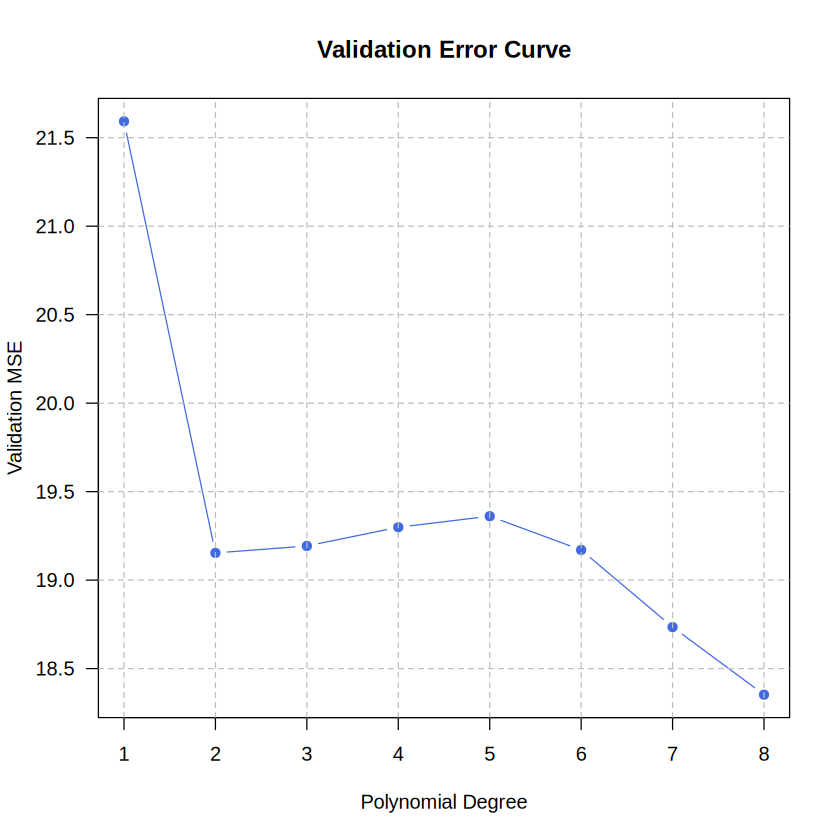

In [57]:
# length(cv.error)
degrees <- 1:8
mse_values <- c(cv.error)
plot(degrees, mse_values, type = "b", pch = 19, col = "royalblue",
     xlab = "Polynomial Degree", ylab = "Validation MSE",
     main = "Validation Error Curve", las = 1)
grid(nx = NULL, ny = NULL, lty = 2, col = "gray")

#K-Fold Cross-Validation
Performing 5 & 10 Fold crossvalidation on mpg ~ acceleration.
Basically partition the set into k equal sections.
Train the model on k-1 folds, and test its performance on the one left out.
do this until each partition has been left once, and been tested against.
last, we take the MSE for our left-out results and plot them. this measures how well the model will do on previously unseen data

_important note_

the partitions are assined randomly so changing the seed value will also change how those partitions are shuffled... which is what causes the final curves to shift with each run

### TASK 4) Select a different feature form Auto than you did in task 3 and perform a 5 fold and 10 fold k-fold cross validation. Again be sure to use your ID as a seed.

In [58]:
#5 Fold CV
set.seed(7829)
cv.error.5 <- rep(0, 5)
for(i in 1:5) {
  glm.fit <- glm(mpg ~ poly(acceleration, i), data = Auto)
  cv.error.5[i] <- cv.glm(Auto, glm.fit, K = 5)$delta[1]
}
cv.error.5

[1] 50.34897 50.18340 50.16309 50.31169 49.46200

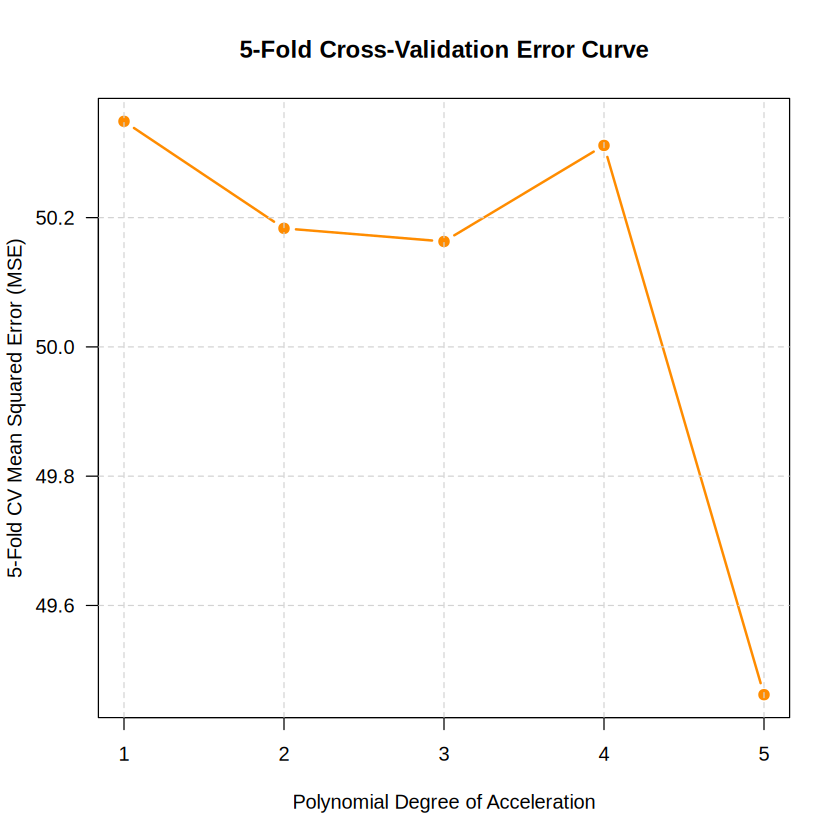

In [59]:
#Disclosure: GEMINI was used to generate the plot
# 1. Generate the base line plot ('b' plots both lines and points)
plot(1:5, cv.error.5, type = "b", pch = 19, col = "darkorange", lwd = 2,
     xlab = "Polynomial Degree of Acceleration",
     ylab = "5-Fold CV Mean Squared Error (MSE)",
     main = "5-Fold Cross-Validation Error Curve", las = 1)

# 2. Add gridlines to isolate the minimum point
grid(nx = NULL, ny = NULL, lty = 2, col = "lightgray")


In [60]:
# 10 Fold CV
set.seed(7829)
cv.error.10 <- rep(0, 10)
for(i in 1:10) {
  glm.fit <- glm(mpg ~ poly(acceleration, i), data = Auto)
  cv.error.10[i] <- cv.glm(Auto, glm.fit, K = 10)$delta[1]
}
cv.error.10

[1] 50.43148 49.67986 50.25249 49.15703 50.57700 49.52525 50.83401 51.53390
 [9] 50.50237 51.14321

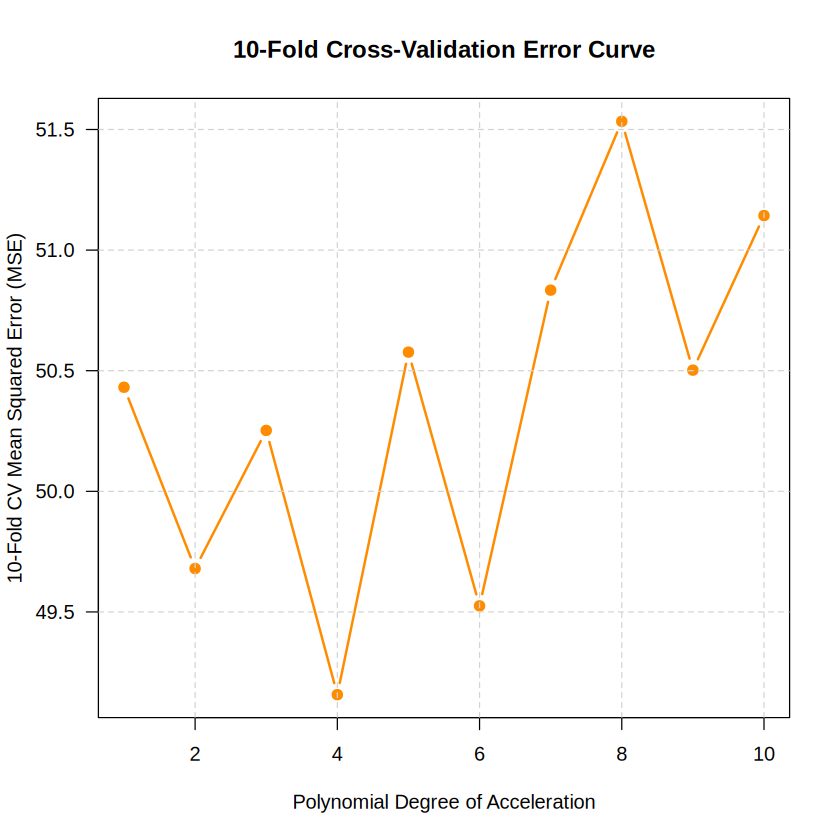

In [61]:
#Disclosure: GEMINI was used to generate the plot

# 1. Generate the base line plot ('b' plots both lines and points)
plot(1:10, cv.error.10, type = "b", pch = 19, col = "darkorange", lwd = 2,
     xlab = "Polynomial Degree of Acceleration",
     ylab = "10-Fold CV Mean Squared Error (MSE)",
     main = "10-Fold Cross-Validation Error Curve", las = 1)

# 2. Add gridlines to isolate the minimum point
grid(nx = NULL, ny = NULL, lty = 2, col = "lightgray")


#The Bootstrap / Bootstrap Analysis
This stat extrapolation tech can be used in almost all situations.
It involves just 2 steps:
- Creating a function that computes some statistic of interest
- the `boot` function - which resamples repetedly with replacement from the original sample

For this section, I will run bootstrap on ISLR2's `Portfolio` dataset to estimate a few global statistic metrics from a sample .

In [62]:
alpha.fn <- function(data, index) {
  X <- data$X[index]
  Y <- data$Y[index]
  (var(Y) - cov(X, Y)) / (var(X) + var(Y) - 2 * cov(X, Y))
}

In [63]:
alpha.fn(Portfolio, 1:100)

[1] 0.5758321

In [64]:
set.seed(7829)
alpha.fn(Portfolio, sample(100, 100, replace = T))

[1] 0.6170244

This automates bootstrap analysis - performing alpha.fn estimation 1000 times

In [65]:
boot(Portfolio, alpha.fn, R = 1000)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Portfolio, statistic = alpha.fn, R = 1000)


Bootstrap Statistics :
     original        bias    std. error
t1* 0.5758321 -0.0006908914  0.09214435

In [66]:
boot.fn <- function(data, index)
  coef(lm(mpg ~ horsepower, data = data, subset = index))
boot.fn(Auto, 1:392)

(Intercept)  horsepower 
 39.9358610  -0.1578447

In [67]:
set.seed(7829)
boot.fn(Auto, sample(392, 392, replace = T))

(Intercept)  horsepower 
 39.1039364  -0.1512773

In [68]:
boot.fn(Auto, sample(392, 392, replace = T))


(Intercept)  horsepower 
 39.8586645  -0.1563317

Running the boot command to compute STDE of 1000 estimates

In [69]:
boot(Auto, boot.fn, 1000)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 1000)


Bootstrap Statistics :
      original        bias    std. error
t1* 39.9358610  0.0171371570 0.861917767
t2* -0.1578447 -0.0002451524 0.007589346

In [70]:
summary(lm(mpg ~ horsepower, data = Auto))$coef

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),39.9358610,0.717498656,55.65984,1.220362e-187
horsepower,-0.1578447,0.006445501,-24.48914,7.031989e-81


In [71]:
boot.fn <- function(data, index)
  coef(
      lm(mpg ~ horsepower + I(horsepower^2),
        data = data, subset = index)
    )
set.seed(7829)
boot(Auto, boot.fn, 1000)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 1000)


Bootstrap Statistics :
        original        bias    std. error
t1* 56.900099702 -6.074540e-03 2.065412058
t2* -0.466189630 -8.689888e-05 0.033028139
t3*  0.001230536  1.151834e-06 0.000119656

In [72]:
summary(
    lm(mpg ~ horsepower + I(horsepower^2), data = Auto)
  )$coef

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),56.900099702,1.8004268063,31.60367,1.740911e-109
horsepower,-0.466189630,0.0311246171,-14.97816,2.289429e-40
I(horsepower^2),0.001230536,0.0001220759,10.08009,2.196340e-21


### Task 5) Compute the last bootstrap exercise (the quadratic fit for horsepower) from the lab 3 more times, using a new number of samples {250, 500, 2500}.

The goal of this task will be to compare the error estimates of the increasing number of samples. Report your observations about the error as the number of bootstrap sets increases.  Again be sure to use your ID as a seed.

In [73]:
set.seed(7829)
boot(Auto, boot.fn, 250)
set.seed(7829)
boot(Auto, boot.fn, 500)
set.seed(7829)
boot(Auto, boot.fn, 2500)


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 250)


Bootstrap Statistics :
        original        bias     std. error
t1* 56.900099702  7.581548e-02 2.0623811586
t2* -0.466189630 -1.080055e-03 0.0327213649
t3*  0.001230536  3.888304e-06 0.0001180775


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 500)


Bootstrap Statistics :
        original        bias    std. error
t1* 56.900099702  9.451283e-02 2.071980039
t2* -0.466189630 -1.417751e-03 0.033009968
t3*  0.001230536  4.995823e-06 0.000119282


ORDINARY NONPARAMETRIC BOOTSTRAP


Call:
boot(data = Auto, statistic = boot.fn, R = 2500)


Bootstrap Statistics :
        original        bias     std. error
t1* 56.900099702  1.655521e-02 2.0983756989
t2* -0.466189630 -3.461653e-04 0.0335085003
t3*  0.001230536  1.877650e-06 0.0001212045

From [R= 250, R = 500, R = 2500],
- intercept error goes from 2.0623 to 2.0719, to 2.0983
- hp error goes frm 0.0327 to 0.0330 to 0.0335
- hp^2 effor goes from 0.000118, to 0.000119 to 0.000121

It is clear from these 3 observations in isolation that std error changed most significantly when increasing our samples quantity from 250 to 500. The error for all estimates (intercept, hp, and hp^2) increase slightly across the interval. From 500 to 2500 we see similar increases across all 3 components

using the sheeps and goats analogy: smaller samples look increasingly less homogenous and therefore statistics extrapolated from them are subject to high variation due to random chance of having an overrepresented subset. increasing the sample quantity statistically homoginizes the exprapolated stats - which gives us a more reliable measure of the true global sample statistic

#Section 2- Classification :

##(1) Logistic Reression
Using one of the the datasets provided above,
Use your plot functions to determine if the distributions are well suited for classification tasks!
Start by implementing your own version of the "Logistic Regression" exercise above#.
-->  Please provide the code you used to train your model, the summary of the model, and a plot of your logistic regression model. The following link includes 2 methods to generate this plot:  (https://www.geeksforgeeks.org/how-to-plot-a-logistic-regression-curve-in-r/)

Im choosing the student performance datasetset
downloading as a csv as the page is down: https://www.kaggle.com/datasets/amar5693/student-performance-dataset

In [74]:
Students <- read.csv("/content/ultimate_student_productivity_dataset_5000.csv")
names(Students)

[1] "student_id"           "age"                  "gender"              
 [4] "academic_level"       "study_hours"          "self_study_hours"    
 [7] "online_classes_hours" "social_media_hours"   "gaming_hours"        
[10] "sleep_hours"          "screen_time_hours"    "exercise_minutes"    
[13] "caffeine_intake_mg"   "part_time_job"        "upcoming_deadline"   
[16] "internet_quality"     "mental_health_score"  "focus_index"         
[19] "burnout_level"        "productivity_score"   "exam_score"

In [75]:
summary(Students)

   student_id        age              gender       academic_level
 Min.   :   1   Min.   :16.00   Length   :5000   Length   :5000  
 1st Qu.:1251   1st Qu.:18.00   N.unique :   3   N.unique :   3  
 Median :2500   Median :20.00   N.blank  :   0   N.blank  :   0  
 Mean   :2500   Mean   :20.52   Min.nchar:   4   Min.nchar:  11  
 3rd Qu.:3750   3rd Qu.:23.00   Max.nchar:   6   Max.nchar:  13  
 Max.   :5000   Max.   :25.00                                    
  study_hours    self_study_hours online_classes_hours social_media_hours
 Min.   : 0.00   Min.   :0.000    Min.   :0.000        Min.   :0.000     
 1st Qu.: 3.25   1st Qu.:1.660    1st Qu.:1.320        1st Qu.:1.990     
 Median : 4.53   Median :2.480    Median :2.010        Median :2.980     
 Mean   : 4.54   Mean   :2.479    Mean   :2.012        Mean   :2.998     
 3rd Qu.: 5.76   3rd Qu.:3.290    3rd Qu.:2.690        3rd Qu.:4.030     
 Max.   :11.84   Max.   :7.410    Max.   :6.000        Max.   :8.280     
  gaming_hours    sl

Here I can see therre are 3 categorical fields:
*   gender
*   academic_level
*   internet_quality

Of these, I would BET that video_game hours and caffene intake would be the biggest predictors of academic level.

Given that age is between 16 and 25, it is probably a good assumption that these acadmic levels range from highschool to college graduates (i googled and the average age of a college bachelor is 22)



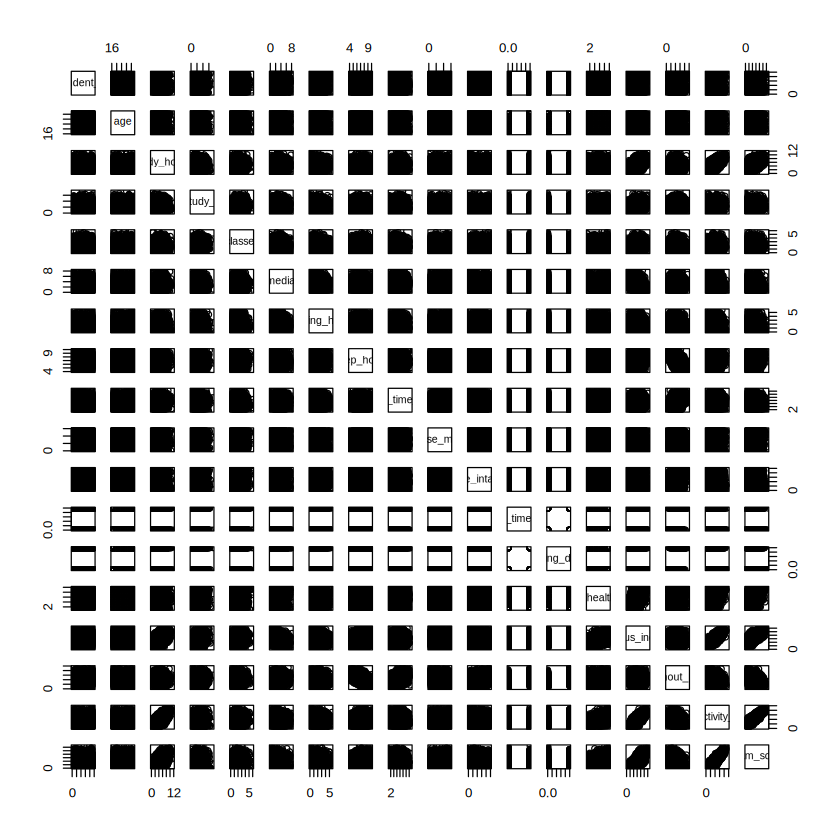

In [76]:
# @title
pairs(Students[,-c(3,4,16)]) #removing qualitative vars

In [77]:
summary(Students)

   student_id        age              gender       academic_level
 Min.   :   1   Min.   :16.00   Length   :5000   Length   :5000  
 1st Qu.:1251   1st Qu.:18.00   N.unique :   3   N.unique :   3  
 Median :2500   Median :20.00   N.blank  :   0   N.blank  :   0  
 Mean   :2500   Mean   :20.52   Min.nchar:   4   Min.nchar:  11  
 3rd Qu.:3750   3rd Qu.:23.00   Max.nchar:   6   Max.nchar:  13  
 Max.   :5000   Max.   :25.00                                    
  study_hours    self_study_hours online_classes_hours social_media_hours
 Min.   : 0.00   Min.   :0.000    Min.   :0.000        Min.   :0.000     
 1st Qu.: 3.25   1st Qu.:1.660    1st Qu.:1.320        1st Qu.:1.990     
 Median : 4.53   Median :2.480    Median :2.010        Median :2.980     
 Mean   : 4.54   Mean   :2.479    Mean   :2.012        Mean   :2.998     
 3rd Qu.: 5.76   3rd Qu.:3.290    3rd Qu.:2.690        3rd Qu.:4.030     
 Max.   :11.84   Max.   :7.410    Max.   :6.000        Max.   :8.280     
  gaming_hours    sl

In [78]:
cor(Students[,-c(3,4,16)])

,student_id,age,study_hours,self_study_hours,online_classes_hours,social_media_hours,gaming_hours,sleep_hours,screen_time_hours,exercise_minutes,caffeine_intake_mg,part_time_job,upcoming_deadline,mental_health_score,focus_index,burnout_level,productivity_score,exam_score
student_id,1.000000000,0.0152230690,-0.0185495173,-0.0201154476,-0.003989196,0.019321659,7.484076e-03,-0.017050466,-0.003595670,-0.0032714781,3.116033e-02,0.009574978,0.015509121,0.008754191,-0.010968069,0.0305469660,-0.023208939,-0.02940626
age,0.015223069,1.0000000000,0.0005109693,0.0048886781,-0.001553479,0.004207223,1.376765e-02,0.004718996,0.001662281,0.0163549935,4.370395e-04,-0.015374569,-0.004409981,-0.023882903,-0.018509360,-0.0135587676,-0.013606663,-0.00904726
study_hours,-0.018549517,0.0005109693,1.0000000000,-0.0039424743,0.011237875,-0.000296366,1.747550e-02,-0.027995157,-0.022898769,-0.0048466543,-1.536237e-02,-0.017780938,-0.012726420,-0.013122000,0.448049893,-0.0008112289,0.637980654,0.51343370
self_study_hours,-0.020115448,0.0048886781,-0.0039424743,1.0000000000,-0.010099752,-0.015581544,5.688747e-04,-0.007137856,-0.016263929,0.0063037345,7.317008e-03,0.017677283,0.001943805,0.011482296,0.237721170,0.0026704170,0.057781075,0.08360238
online_classes_hours,-0.003989196,-0.0015534790,0.0112378752,-0.0100997522,1.000000000,-0.011795909,-6.787736e-03,-0.013043213,-0.022199078,0.0254511404,7.213305e-03,-0.013239317,0.001453994,-0.006294875,0.007709348,-0.0212040397,0.003214917,0.00497491
social_media_hours,0.019321659,0.0042072226,-0.0002963660,-0.0155815441,-0.011795909,1.000000000,1.025078e-02,0.003534885,-0.016412321,0.0131584793,-2.571871e-02,0.002860833,-0.004025519,-0.008081103,-0.314477922,-0.0230761105,-0.070051804,-0.10611568
gaming_hours,0.007484076,0.0137676458,0.0174754951,0.0005688747,-0.006787736,0.010250780,1.000000e+00,-0.022216613,-0.005403144,-0.0001762522,-7.556238e-06,-0.015833192,0.010175066,-0.008616041,-0.176750658,0.0107014078,-0.029410867,-0.05450642
sleep_hours,-0.017050466,0.0047189957,-0.0279951573,-0.0071378562,-0.013043213,0.003534885,-2.221661e-02,1.000000000,-0.009720031,0.0076242450,-9.662899e-03,0.006228574,0.002717343,0.002121533,0.158236371,-0.4929346975,0.149665921,0.23470955
screen_time_hours,-0.003595670,0.0016622815,-0.0228987693,-0.0162639290,-0.022199078,-0.016412321,-5.403144e-03,-0.009720031,1.000000000,0.0106806156,-2.654947e-02,0.021272567,-0.020136664,0.015780277,-0.008281403,0.3406515548,-0.089953284,-0.13194032
exercise_minutes,-0.003271478,0.0163549935,-0.0048466543,0.0063037345,0.025451140,0.013158479,-1.762522e-04,0.007624245,0.010680616,1.0000000000,-3.012522e-02,-0.005722918,-0.004023024,-0.009910845,-0.016379999,-0.1573108945,0.020441210,0.04072427


My assumptions were wrong. Videogame hours and caffene have almost no correlation with any of the other quantitative values.

Top 3 correlations are actually
  - productivity score x examscore ~.88
  - productivity score x focus index ~.78
  - Exam score x focus index~.75

In [79]:
attach(Students)

The following objects are masked from Students (pos = 9):

    academic_level, age, burnout_level, caffeine_intake_mg, exam_score,
    exercise_minutes, focus_index, gaming_hours, gender,
    internet_quality, mental_health_score, online_classes_hours,
    part_time_job, productivity_score, screen_time_hours,
    self_study_hours, sleep_hours, social_media_hours, student_id,
    study_hours, upcoming_deadline




In [80]:
# plot(productivity_score)
# plot(exam_score)
# plot(focus_index)
# plot(age)

In [81]:
glm.fits <- glm( #baseline
  #removing categorical fielgender + internet_quality
  academic_level=="Postgraduate" ~ age + burnout_level + caffeine_intake_mg + exam_score + exercise_minutes + focus_index + gaming_hours + mental_health_score + online_classes_hours + part_time_job + productivity_score + screen_time_hours + self_study_hours + sleep_hours + social_media_hours + student_id + study_hours + upcoming_deadline,
  data = Students, family = binomial
)
summary(glm.fits)


Call:
glm(formula = academic_level == "Postgraduate" ~ age + burnout_level + 
    caffeine_intake_mg + exam_score + exercise_minutes + focus_index + 
    gaming_hours + mental_health_score + online_classes_hours + 
    part_time_job + productivity_score + screen_time_hours + 
    self_study_hours + sleep_hours + social_media_hours + student_id + 
    study_hours + upcoming_deadline, family = binomial, data = Students)

Coefficients:
                       Estimate Std. Error z value Pr(>|z|)  
(Intercept)           5.766e-01  4.604e-01   1.252   0.2104  
age                  -1.355e-02  1.045e-02  -1.296   0.1948  
burnout_level        -7.281e-03  5.414e-03  -1.345   0.1786  
caffeine_intake_mg    5.067e-04  2.319e-04   2.185   0.0289 *
exam_score           -6.624e-03  6.075e-03  -1.090   0.2755  
exercise_minutes     -6.297e-04  7.397e-04  -0.851   0.3946  
focus_index           6.924e-03  6.683e-03   1.036   0.3002  
gaming_hours          1.124e-02  2.858e-02   0.393   0.6942  
ment

Interesting:
the 3 lowest p values are
- sleep hours - 0.0238
- caffene intake - 0.0289
- upcoming deadline - 0.0372

###Fitting

In [82]:
glm.fits <- glm( #fitting with sleeping hours and caffene intake
  #removing categorical field gender + internet_quality
  academic_level=="Postgraduate" ~ sleep_hours + caffeine_intake_mg,
  data = Students, family = binomial
)
summary(glm.fits)


Call:
glm(formula = academic_level == "Postgraduate" ~ sleep_hours + 
    caffeine_intake_mg, family = binomial, data = Students)

Coefficients:
                     Estimate Std. Error z value Pr(>|z|)  
(Intercept)        -0.4869487  0.1905113  -2.556   0.0106 *
sleep_hours        -0.0400611  0.0257335  -1.557   0.1195  
caffeine_intake_mg  0.0003672  0.0002082   1.764   0.0778 .
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 6393.0  on 4999  degrees of freedom
Residual deviance: 6387.4  on 4997  degrees of freedom
AIC: 6393.4

Number of Fisher Scoring iterations: 4


In [83]:
summary(glm.fits)$coef

,Estimate,Std. Error,z value,Pr(>|z|)
(Intercept),-0.4869487444,0.1905113278,-2.556009,0.01058803
sleep_hours,-0.0400611169,0.0257334665,-1.556771,0.11952484
caffeine_intake_mg,0.0003671546,0.0002081822,1.763622,0.07779571


**quick aside** but really cool observation:
look at studentID. my original assumption was that student id would negatively correlate with academic status because if they are issued serially, it would make sence that higher numbers correspond to younger / newer students....

edit... i thought about it longer, I realized the spread spans Highschool and College - which almost certantly would be disjointed ranges

----
predicting postgrad student status given all the predictors like in the lab - will use top predictors later.

In [84]:
glm.probs <- predict(glm.fits, Students, type = "response")
glm.probs[1:10]

1         2         3         4         5         6         7         8 
0.3242748 0.3539667 0.3262053 0.3627380 0.3102338 0.3284248 0.3215509 0.3422997 
        9        10 
0.3304895 0.3653747

In [85]:
contrasts(academic_level == "Postgraduate")

,TRUE
FALSE,0
TRUE,1


# Post-EDA

In [86]:
Students$postgrad <- academic_level == "Postgraduate" #Boolean response column matching postrgad evaluation

In [87]:
train <- Students$student_id <=4000 # Boolean vector matching the condition per our training set -> 4k observations;
train.set <- Students[train, ]
test.set <- Students[!train,]

In [88]:
# @title
# Students.4000 <- academic_level=="Postgraduate"[!train]
# print(Students.4000)

(disregard both commented sections below - but keeping commented to show effort / ruminations related to test validation splits)
- it dawned on me that since there is no time series like in the lab, serial studentids might work as good analogs for ordering, so i split with the implementation above rather than the commented code below from subset selection.

In [89]:
# @title
# validation.split <- function(total_pop, trainPercentage) {
#   #Resetting the seed for each split to ensure we are comparing apples to apples
#   #otherwise the seed with drift with each sample call (within validation.split)
#   set.seed(7829)
#   return (sample(total_pop, total_pop*trainPercentage))
# }

In [90]:
# @title
# library(glue) #printing values / interpolation
# holdout <- validation.split(5000, 0.20) #1000
# # dim(Students)
# test <- Students[holdout,] #randomly selected test set
# train <- Students[-holdout,] #Training with the negation
# glue("test dim: {nrow(test)}, train dim: {nrow(train)}")

**Training**

We now fit a logistic regression model using only the subset of the observations that correspond to the first 4000 StudentIds, stored in our train.set .

In [91]:
glm.fits <- glm( postgrad ~ sleep_hours + caffeine_intake_mg,
  data = train.set, family = binomial
)
summary(glm.fits)


Call:
glm(formula = postgrad ~ sleep_hours + caffeine_intake_mg, family = binomial, 
    data = train.set)

Coefficients:
                     Estimate Std. Error z value Pr(>|z|)  
(Intercept)        -0.5037682  0.2136474  -2.358   0.0184 *
sleep_hours        -0.0333199  0.0287924  -1.157   0.2472  
caffeine_intake_mg  0.0003258  0.0002326   1.401   0.1613  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 5137.5  on 3999  degrees of freedom
Residual deviance: 5134.2  on 3997  degrees of freedom
AIC: 5140.2

Number of Fisher Scoring iterations: 4


**Testing**
obtaining the probability a given person is a graduate student given their sleep hours and caffene intake

In [92]:
glm.probs <- predict(glm.fits, test.set, type = "response")
glm.pred <- ifelse(glm.probs > 0.33, "Grad", "Non-Grad")
actual <- ifelse(test.set$postgrad, "Grad", "Non-Grad")

**academic_level**

 Min.   :   1   Min.   :16.00   Length   :5000   Length   :5000  
 1st Qu.:1251   1st Qu.:18.00   N.unique :   3   **N.unique :   3**
 Median :2500   Median :20.00   N.blank  :   0   N.blank  :   0  
 Mean   :2500   Mean   :20.52   Min.nchar:   4   Min.nchar:  11  
 3rd Qu.:3750   3rd Qu.:23.00   Max.nchar:   6   Max.nchar:  13

In [93]:
table(glm.pred, actual) #Confusion Matrix

          actual
glm.pred   Grad Non-Grad
  Grad      265      541
  Non-Grad   55      139

In [94]:
library(glue)
acc <- (265 + 139)/(265 + 541 + 55 + 139)

glue("accuracy = {acc}")

accuracy = 0.404

####Plotting

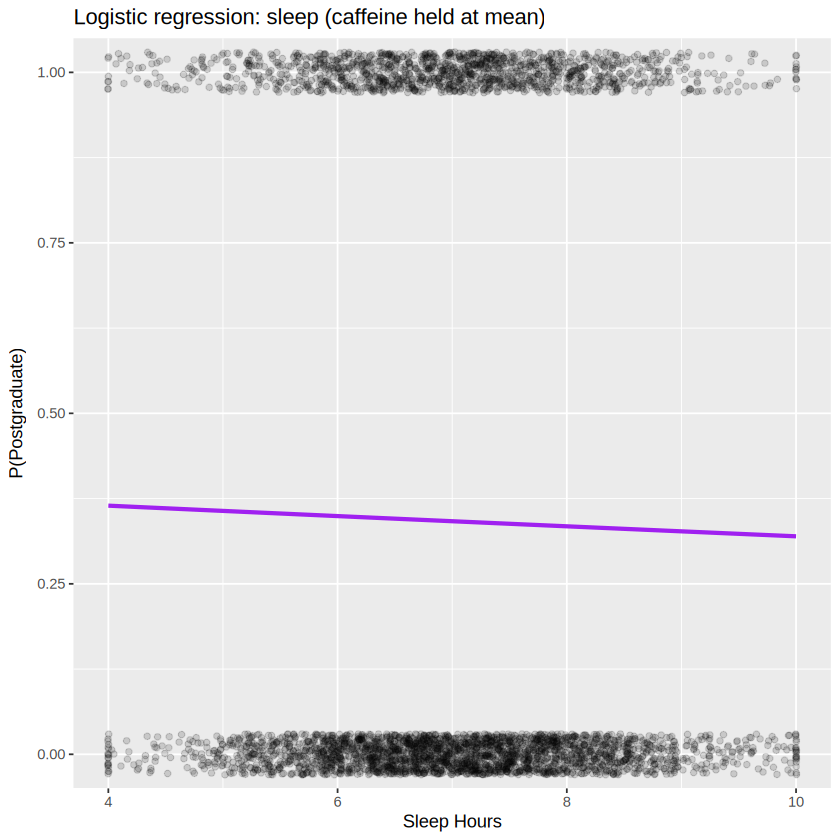

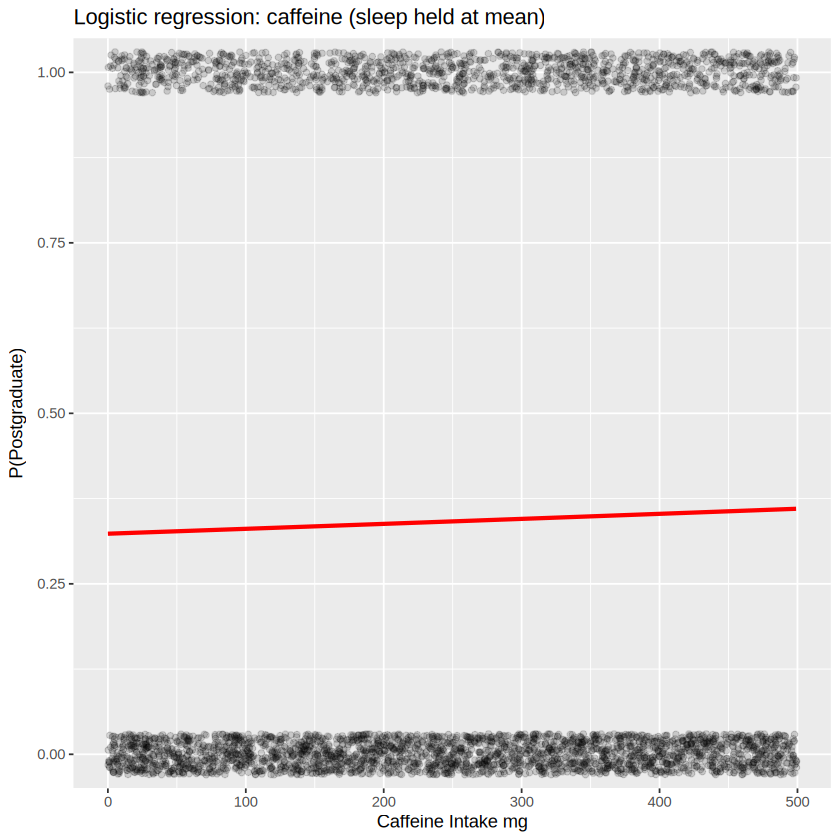

In [95]:
# @title
library(ggplot2)

sleep.grid <- seq(min(train.set$sleep_hours), max(train.set$sleep_hours), length.out = 200)
caff.grid  <- seq(min(train.set$caffeine_intake_mg), max(train.set$caffeine_intake_mg), length.out = 200)

sleep.df <- data.frame(sleep_hours = sleep.grid,
                       caffeine_intake_mg = mean(train.set$caffeine_intake_mg))
caff.df  <- data.frame(sleep_hours = mean(train.set$sleep_hours),
                       caffeine_intake_mg = caff.grid)

sleep.df$prob <- predict(glm.fits, sleep.df, type = "response")
caff.df$prob  <- predict(glm.fits, caff.df,  type = "response")

y <- as.numeric(train.set$postgrad)   # 0/1

library(ggplot2)

ggplot(train.set, aes(x = sleep_hours, y = as.numeric(postgrad))) +
  geom_jitter(height = 0.03, alpha = 0.15) +
  geom_line(data = sleep.df, aes(x = sleep_hours, y = prob), color = "purple", linewidth = 1.2) +
  coord_cartesian(ylim = c(0, 1)) +
  labs(x="Sleep Hours", y= "P(Postgraduate)", title = "Logistic regression: sleep (caffeine held at mean)")


ggplot(train.set, aes(x = caffeine_intake_mg, y = as.numeric(postgrad))) +
  geom_jitter(height = 0.03, alpha = 0.15) +
  geom_line(data = caff.df, aes(x = caffeine_intake_mg, y = prob), color = "red", linewidth = 1.2) +
  coord_cartesian(ylim = c(0, 1)) +
  labs(x = "Caffeine Intake mg", y = "P(Postgraduate)",
       title = "Logistic regression: caffeine (sleep held at mean)")


#(2) LDA
Using the same data from part 1, apply the "Linear Discriminate" method. Include the class predictions for your trained model, then plot the results for the  and compare the results.
-- > Please provide your code, relevant summary/metrics and plots for your model using plot(lda.fit) [as given in the lab] or pairs.lda (MASS).

In [96]:
library(MASS)
lda.fit <- lda(postgrad ~ sleep_hours + caffeine_intake_mg, data = Students, subset = train)
lda.fit

Call:
lda(postgrad ~ sleep_hours + caffeine_intake_mg, data = Students, 
    subset = train)

Prior probabilities of groups:
  FALSE    TRUE 
0.65825 0.34175 

Group means:
      sleep_hours caffeine_intake_mg
FALSE    7.039043           248.4284
TRUE     6.993511           255.2114

Coefficients of linear discriminants:
                            LD1
sleep_hours        -0.545696422
caffeine_intake_mg  0.005335887

In [97]:
# Group means:
#       sleep_hours caffeine_intake_mg
# FALSE    7.039043           248.4284
# TRUE     6.993511           255.2114

On average, graduate students tend to sleep slightly less and consume slightly more caffeine but with pvalues > 0.07, this could just be noise/ variance in the sample

Priors = isPostgrad percentage(training):
  - FALSE : 0.65825 correspond to nongrad records
  - TRUE: 0.34175


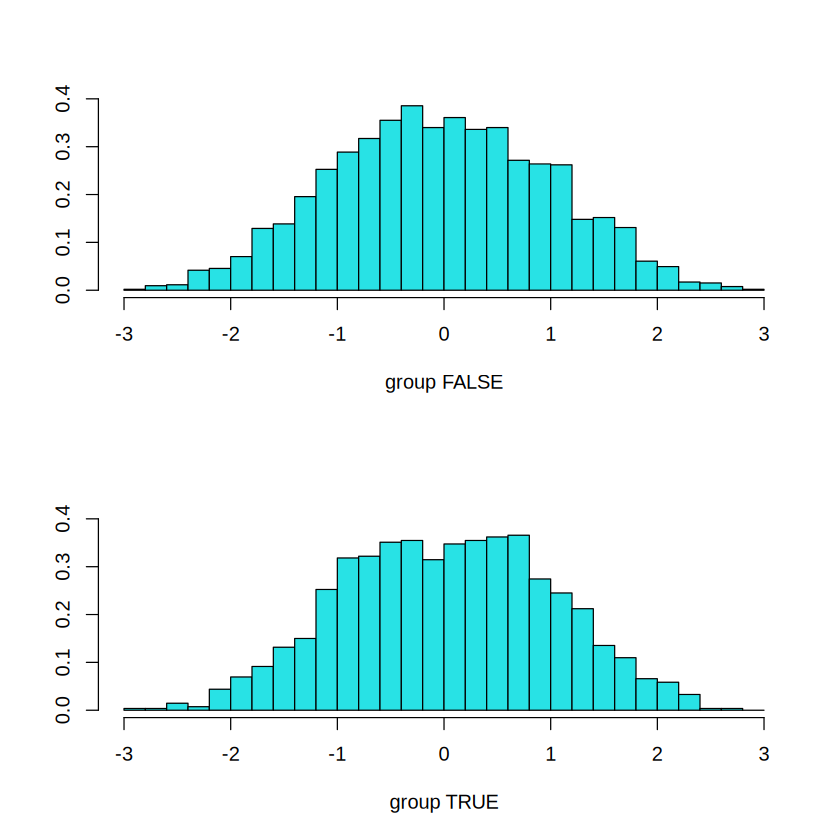

In [98]:
plot(lda.fit)

2) there is no obvious line you can draw to separate the 2 groups - they overlap almost perfectly

In [99]:
lda.pred <- predict(lda.fit, test.set) #1000 test records
#'class''posterior''x'
names(lda.pred)

[1] "class"     "posterior" "x"

In [100]:
lda.class <- lda.pred$class #boolean array for isgrad
lda.label <- ifelse(lda.class == "TRUE", "Grad", "Non-Grad")
table(lda.label, actual)

          actual
lda.label  Grad Non-Grad
  Non-Grad  320      680

In [101]:
mean(lda.label == actual)

[1] 0.68

###Testing 50% posterior

In [102]:
#experementing - applying 50% posterior threshold in lab
sum(lda.pred$posterior[,2] >= .5)
sum(lda.pred$posterior[,2] <  .5)

[1] 0

[1] 1000

with a 50% posterior, lda predicts non grad for all 1000 students so the mean evaluation of 0.68 is just the proportion of non-grad students

the lda model predicted postgraduate academic status as true in 0 / 1000 observations.

Grad students dont make up half of the data, they just make up ~33%

Trying with the even.33 cut off used in the logistic regression

In [103]:
lda.label.33 <- ifelse(lda.pred$posterior[, 2] > 0.33, "Grad", "Non-Grad")
table(lda.label.33, actual)
mean(lda.label.33 == actual)

            actual
lda.label.33 Grad Non-Grad
    Grad      266      541
    Non-Grad   54      139

[1] 0.405

In [104]:
sum(lda.pred$posterior[, 2] >= .33)
sum(lda.pred$posterior[, 2] <  .33)

[1] 807

[1] 193

with the posterior set to 33%, lda predicts Grad with 807 observations and non-grad on 193.

The confusion matrix reviels an accuracy of 0.405 - almost exactly the same as Logistic Regression's 0.404

###3) Implement and assess a Classification model:
A ) Select a dataset and classification TARGET and select the relevant features you wish to use. [You may use data from ISLR or MASS -- or one of the sets above].
You can either choose a binary classification (where applicable) or a multi-class target using the LDA method.
You may use either a single factor classification (only one feature) or multiple features (I suggest you limit your selection to 5). -- No performance metrics are required in this case, we will assess feature selection in a later assignment.
Select the division scale (test set size) and perform a fit for your model on the training data.


In [105]:
#keeping caffene and sleep hours as prdictors.
#fitting age, and screentime hours -
#Im kindof just assuming age would be a good analog for academic seniority,
#and screentime hours would be a good reverse indicator - grad students have more work, and less time for screens


In [106]:
target <- "academic_level"
predictors <- c("age", "screen_time_hours", "sleep_hours", "caffeine_intake_mg")

Students.4 <- Students[,c(target, predictors)]
Students.4$academic_level <- factor(Students.4$academic_level)


creating testing and training set. holding out 20%

In [107]:
set.seed(7829)
# length(sample(nrow(Students.4), .2 * nrow(Students.4)))
test.idx <- sample(nrow(Students.4), .2 * nrow(Students.4))
train.m <- Students.4[-test.idx,]
test.m <- Students.4[test.idx, ]

glue("Training dim: {dim(train.m)[1]}, Testing dim: {dim(test.m)[1]}")


Training dim: 4000, Testing dim: 1000

In [108]:
table(train.m$academic_level)
table(test.m$academic_level)


  High School  Postgraduate Undergraduate 
         1354          1329          1317 


  High School  Postgraduate Undergraduate 
          318           358           324 

In [109]:
glue("Training ---- HIGHSCHOOL: {1354/4000} Postgraduate:{1329/4000} Undergraduate:{1317 /4000}")
glue("Testing ---- HIGHSCHOOL: {318/1000} Postgraduate:{358/1000} Undergraduate:{324 /1000}")

Training ---- HIGHSCHOOL: 0.3385 Postgraduate:0.33225 Undergraduate:0.32925

Testing ---- HIGHSCHOOL: 0.318 Postgraduate:0.358 Undergraduate:0.324

In [110]:
lda.multi <- lda(academic_level ~ ., data = train.m)
lda.multi
holdout.pred <- predict(lda.multi, test.m)$class
table(holdout.pred, test.m$academic_level)

Call:
lda(academic_level ~ ., data = train.m)

Prior probabilities of groups:
  High School  Postgraduate Undergraduate 
      0.33850       0.33225       0.32925 

Group means:
                   age screen_time_hours sleep_hours caffeine_intake_mg
High School   20.47120          7.046514    7.081366           253.9284
Postgraduate  20.49210          6.899940    6.982129           258.2897
Undergraduate 20.67654          6.934207    7.000471           242.5406

Coefficients of linear discriminants:
                            LD1          LD2
age                -0.194862127 -0.014523234
screen_time_hours   0.082931241 -0.207679781
sleep_hours         0.283082069 -0.630523812
caffeine_intake_mg  0.005144102  0.002956369

Proportion of trace:
   LD1    LD2 
0.6296 0.3704 

               
holdout.pred    High School Postgraduate Undergraduate
  High School           130          139           137
  Postgraduate           89          113            91
  Undergraduate          99          106            96

In [111]:
mean(holdout.pred == test.m$academic_level)# test accuracy
max(prop.table(table(Students.4$academic_level)))# baseline

[1] 0.339

[1] 0.3374

It turns out these were bad predictors as well. looking at the group means for age sleep hours, and screentime hours, the range of these values differ by no more than .2 and caffene intake in mg is negligible at 16mg (out of ~250mg)

#### K-Fold Cross Validation

In [112]:
glue("----K=5-----")

K <- 5
set.seed(7829)
folds <- sample(rep(1:K, length.out = nrow(Students.4)))

cv.error.5 <- rep(0, K)
pred.all.5 <- factor(rep(NA, nrow(Students.4)), levels = levels(Students.4$academic_level))

for (i in 1:K) {
  lda.fit <- lda(academic_level ~ ., data = Students.4[folds != i, ])
  pred    <- predict(lda.fit, Students.4[folds == i, ])$class
  cv.error.5[i] <- mean(pred != Students.4$academic_level[folds == i])
  pred.all.5[folds == i] <- pred
}

glue("
base error: {cv.error.5},
mean error: {mean(cv.error.5)},
accuracy: {1 - mean(cv.error.5)},
variance between folds: {sd(cv.error.5)}")

cv.error.5
mean(cv.error.5)
1 - mean(cv.error.5)
sd(cv.error.5)
table(pred.all.5, Students.4$academic_level)


glue("----K=10-----")
K <- 10
set.seed(7829)
folds <- sample(rep(1:K, length.out = nrow(Students.4)))

cv.error.10 <- rep(0, K)
pred.all.10 <- factor(rep(NA, nrow(Students.4)), levels = levels(Students.4$academic_level))

for (i in 1:K) {
  lda.fit <- lda(academic_level ~ ., data = Students.4[folds != i, ])
  pred    <- predict(lda.fit, Students.4[folds == i, ])$class
  cv.error.10[i] <- mean(pred != Students.4$academic_level[folds == i])
  pred.all.10[folds == i] <- pred
}

glue("
base error: {cv.error.10},
mean error: {mean(cv.error.10)},
accuracy: {1 - mean(cv.error.10)},
STD: {sd(cv.error.10)}")

table(pred.all.10, Students.4$academic_level)





----K=5-----

base error: 0.646,
mean error: 0.6618,
accuracy: 0.3382,
variance between folds: 0.0119666202413213
base error: 0.662,
mean error: 0.6618,
accuracy: 0.3382,
variance between folds: 0.0119666202413213
base error: 0.667,
mean error: 0.6618,
accuracy: 0.3382,
variance between folds: 0.0119666202413213
base error: 0.678,
mean error: 0.6618,
accuracy: 0.3382,
variance between folds: 0.0119666202413213
base error: 0.656,
mean error: 0.6618,
accuracy: 0.3382,
variance between folds: 0.0119666202413213

[1] 0.646 0.662 0.667 0.678 0.656

[1] 0.6618

[1] 0.3382

[1] 0.01196662

               
pred.all.5      High School Postgraduate Undergraduate
  High School           566          554           538
  Postgraduate          640          656           634
  Undergraduate         466          477           469

----K=10-----

base error: 0.628,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.638,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.652,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.674,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.63,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.674,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.67,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.656,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.674,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396
base error: 0.64,
mean error: 0.6536,
accuracy: 0.3464,
STD: 0.0187569246472396

               
pred.all.10     High School Postgraduate Undergraduate
  High School           551          505           511
  Postgraduate          655          710           659
  Undergraduate         466          472           471

1) Did your performance assessment of the model generated change based on the results of your k-fold analsys?


    No
- 80/20 holdout = 0.339
- K = 5:  0.338
- K = 10: 0.346
- Baseline / 100% Postgraduate prediction:  0.337

- pure chance is 1/3 ->  .33 accuracy. The standard deviation between folds / samples: ~0.019, because STD between folds exceeds the difference between the baseline and average errors, the difference is small enough to be considered noise



2) What properties or limitations of your dataset (or selected predictors) do you feel most contributed to shortcomings in model performance (if your models are very low accuracy, be sure to emphasize this response as it may help your score to be able to explain why your efforts didn't generate good* results).
*good results are relative to each dataset, but true classification ratios of <60% are generally considered very limited in their utility.
  - I chose bad features based on flawed assumptions. From my own experience, I expected that sleep and caffeine intake would be good features to correlate with post graduate academic status, but I was wrong
    - The LDA plots show that these 2 predictors basically eclipsed eachother: 3 of the 4 fields differed by about .2 units at most between classes, and caffeine differed by only 16 mg out of 250 (See Screenshot)
  - Later I tried to compensate by adding other features to the fit. Adding more features didnt help. They were just as uninformattive as the the first 2.
  - Unfortunately, this model has about the same utility as RNG
    

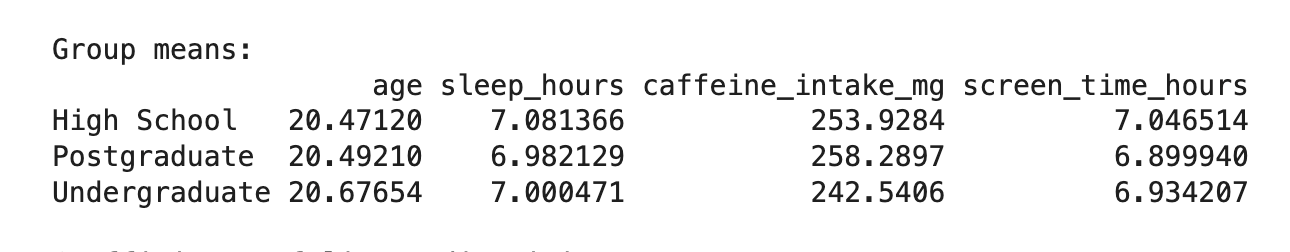

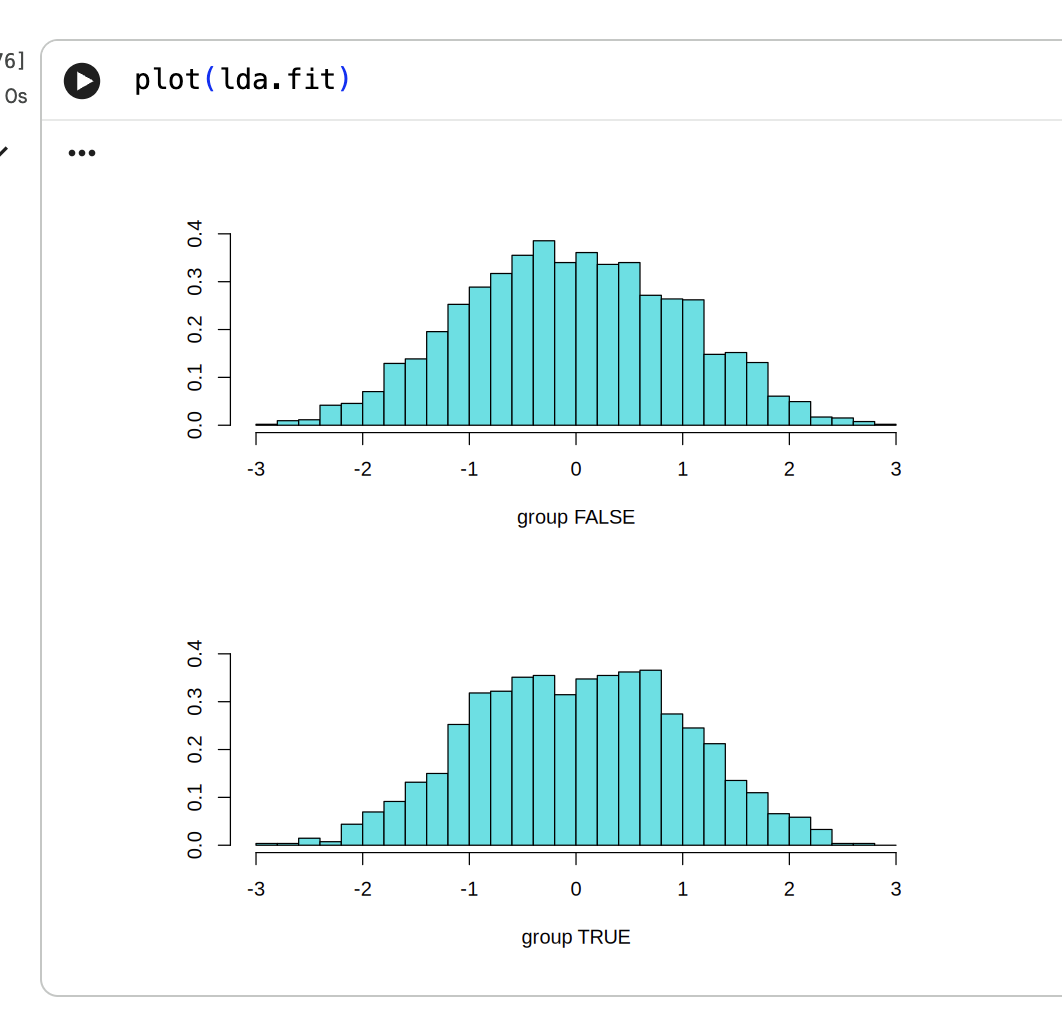